In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from hurst import compute_Hc

In [2]:
## Fetching Dow Jones Data (2007-2009)

In [3]:
ticker = "^DJI"  # Dow Jones Industrial Average ticker
data = yf.download(ticker, start="2007-01-01", end="2009-12-31")
data['Returns'] = data['Adj Close'].pct_change().dropna()  # Daily returns
data['Rolling Mean'] = data['Adj Close'].rolling(window=30).mean()  # 30-day rolling mean
data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume,Returns,Rolling Mean
Ticker,^DJI,^DJI,^DJI,^DJI,^DJI,^DJI,,
Date,,,,,,,,
2007-01-03 00:00:00+00:00,12474.519531,12474.519531,12580.349609,12404.820312,12459.540039,327200000,NaN,NaN
2007-01-04 00:00:00+00:00,12480.690430,12480.690430,12510.410156,12403.860352,12473.160156,259060000,0.000495,NaN
2007-01-05 00:00:00+00:00,12398.009766,12398.009766,12480.129883,12365.410156,12480.049805,235220000,-0.006625,NaN
2007-01-08 00:00:00+00:00,12423.490234,12423.490234,12445.919922,12337.370117,12392.009766,223500000,0.002055,NaN
2007-01-09 00:00:00+00:00,12416.599609,12416.599609,12466.429688,12369.169922,12424.769531,225190000,-0.000555,NaN


In [4]:
## Function to Compute the Hurst Exponent

In [5]:
def rolling_hurst(data, window_size=100):
    """
    Compute the Hurst exponent on a rolling basis.
    
    Parameters:
        data (numpy.ndarray): Array of values to calculate the Hurst exponent.
        window_size (int): Size of the rolling window.
        
    Returns:
        list: Hurst exponent values for each rolling window.
    """
    hurst_values = []
    for i in range(window_size, len(data)):
        series = data[i - window_size:i]
        if len(series) >= 100:  # Hurst calculation requires at least 100 data points
            H, c, data_rs = compute_Hc(series, kind='price', simplified=True)
            hurst_values.append(H)
        else:
            hurst_values.append(np.nan)
    return hurst_values

In [6]:
## Calculate the Hurst Exponent

In [7]:
window_size = 100  # 100-day rolling window
hurst_values = rolling_hurst(data['Adj Close'].dropna().values, window_size=window_size)
hurst_dates = data.index[window_size:]

In [8]:
## Function to Plot Dow Jones Data and Hurst Exponent

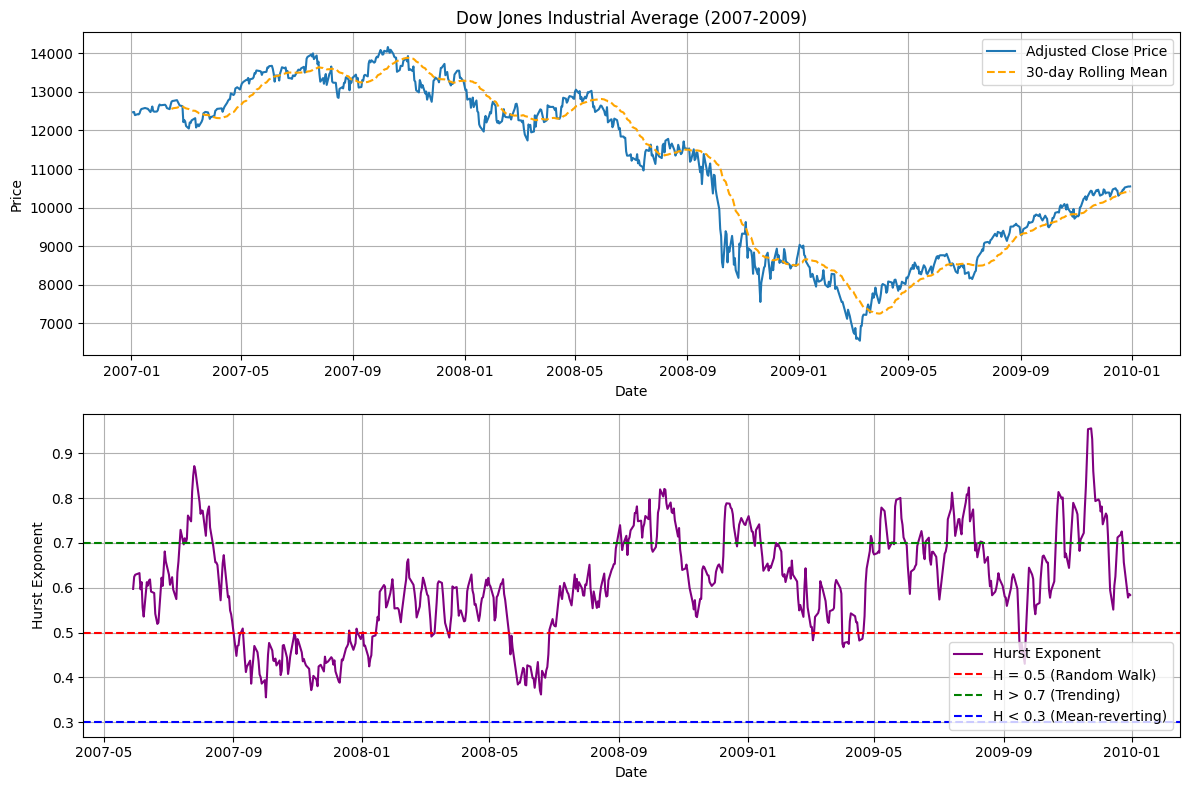

In [9]:
# Plot Adjusted Close Prices and Hurst Exponent
plt.figure(figsize=(12, 8))

# Top plot: Adjusted Close Prices
plt.subplot(2, 1, 1)
plt.plot(data.index, data['Adj Close'], label="Adjusted Close Price")
plt.plot(data.index, data['Rolling Mean'], label="30-day Rolling Mean", linestyle='--', color='orange')
plt.title("Dow Jones Industrial Average (2007-2009)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

# Bottom plot: Hurst Exponent
plt.subplot(2, 1, 2)
plt.plot(hurst_dates, hurst_values, color='purple', label="Hurst Exponent")
plt.axhline(0.5, color='red', linestyle='--', label="H = 0.5 (Random Walk)")
plt.axhline(0.7, color='green', linestyle='--', label="H > 0.7 (Trending)")
plt.axhline(0.3, color='blue', linestyle='--', label="H < 0.3 (Mean-reverting)")
plt.xlabel("Date")
plt.ylabel("Hurst Exponent")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()